# Part A

In [14]:

import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.decomposition import PCA

In [15]:
print("Downloading GISETTE dataset directly from UCI URLs")

data_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/gisette/GISETTE/gisette_train.data"
labels_irl = "https://archive.ics.uci.edu/ml/machine-learning-databases/gisette/GISETTE/gisette_train.labels"

X = pd.read_csv(data_url, sep = r'\s+', header=None)
X = X.iloc[:, :5000]
X = X.astype(float)
y = pd.read_csv(labels_irl, header=None).values.ravel()

In [16]:
print(f"Observation: {X.shape[0]}")
print(f"Input Features: {X.shape[1]}")

unique_classes, counts = np.unique(y, return_counts=True)
print(f"Class Distribution: {dict(zip(unique_classes.tolist(), counts.tolist()))}")

#Chekc missing values
missing_values = X.isnull().sum().sum()
print(f"Missing Values: {missing_values}")

#Measure aprx memory use by feature matrix
memory_mb = X.memory_usage(deep=True).sum() / (1024 * 1024)
print(f"Approximate memory occupied: {memory_mb: .2f} MB")

print("""Explanation: 
5000 features create computational difficulties by significant increasing overhead and matrix multiplication times during training. 
Mostly sized datasets with high dimensinality are also high susceptible to overfitting.
""")

Observation: 6000
Input Features: 5000
Class Distribution: {-1: 3000, 1: 3000}
Missing Values: 0
Approximate memory occupied:  228.88 MB
Explanation: 
5000 features create computational difficulties by significant increasing overhead and matrix multiplication times during training. 
Mostly sized datasets with high dimensinality are also high susceptible to overfitting.



# Part B

In [17]:

#Split the data into 80% training and 20% testing 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=43, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

lr_baseline = LogisticRegression(max_iter=1000, random_state=42)

start_time = time.time()
lr_baseline.fit(X_train_scaled, y_train)
baseline_train_time = time.time() - start_time

baseline_preds = lr_baseline.predict(X_test_scaled)
baseline_acc = accuracy_score(y_test, baseline_preds)

baseline_train_mem_mb = X_train_scaled.nbytes / (1024 * 1024)

print(f"Baseline Test Accuracy: {baseline_acc * 100:.2f}%")
print(f"Baseline Classifier Training Time: {baseline_train_time:.4f} seconds")
print(f"Approximate Training-Matrix Memory: {baseline_train_mem_mb:.2f} MB")

Baseline Test Accuracy: 97.75%
Baseline Classifier Training Time: 0.2640 seconds
Approximate Training-Matrix Memory: 183.11 MB


# Part C & D

In [18]:
pca_config = [50, 100, 200, 500]
results = []

for n_components in pca_config:
    pca = PCA(n_components=n_components, random_state=42)
    
    start_pca = time.time()
    X_train_pca = pca.fit_transform(X_train_scaled)
    X_test_pca = pca.transform(X_test_scaled)
    pca_time = time.time() - start_pca 
    
    variance_retained = np.sum(pca.explained_variance_ratio_) * 100
    reduction_pct = ((5000 - n_components) / 5000) * 100
    pca_mem_mb = X_train_pca.nbytes / (1024 * 1024) 
    
    lr_pca = LogisticRegression(max_iter=1000, random_state=42)
    start_lr = time.time()
    lr_pca.fit(X_train_pca, y_train)
    lr_train_time = time.time() - start_lr
    
    lr_pca_pred = lr_pca.predict(X_test_pca)
    pca_acc = accuracy_score(y_test, lr_pca_pred) * 100
    
    results.append({
        'Method': f'PCA-{n_components}',
        'Input Dimensions': n_components,
        'Reduction %': reduction_pct,
        'Variance Retained %': variance_retained,
        'Test Accuracy %': pca_acc,
        'PCA Time (s)': pca_time,
        'LR Train TIme (s)': lr_train_time,
        'Train Memory (MB)': pca_mem_mb
    })
    
results.insert(0, {
        'Method': 'Original',
        'Input Dimensions': 5000,
        'Reduction %': 0.0,
        'Variance Retained %': 100.0,
        'Test Accuracy %': baseline_acc * 100,
        'PCA Time (s)': 0.0,
        'LR Train TIme (s)': baseline_train_time,
        'Train Memory (MB)': baseline_train_mem_mb
    })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

  Method  Input Dimensions  Reduction %  Variance Retained %  Test Accuracy %  PCA Time (s)  LR Train TIme (s)  Train Memory (MB)
Original              5000          0.0           100.000000        97.750000      0.000000           0.263984         183.105469
  PCA-50                50         99.0            26.163887        96.416667      1.117149           0.023027           1.831055
 PCA-100               100         98.0            32.535966        97.083333      1.561723           0.041019           3.662109
 PCA-200               200         96.0            39.946061        97.500000      2.545309           0.046086           7.324219
 PCA-500               500         90.0            54.740171        97.333333      1.784303           0.031791          18.310547


# Part E

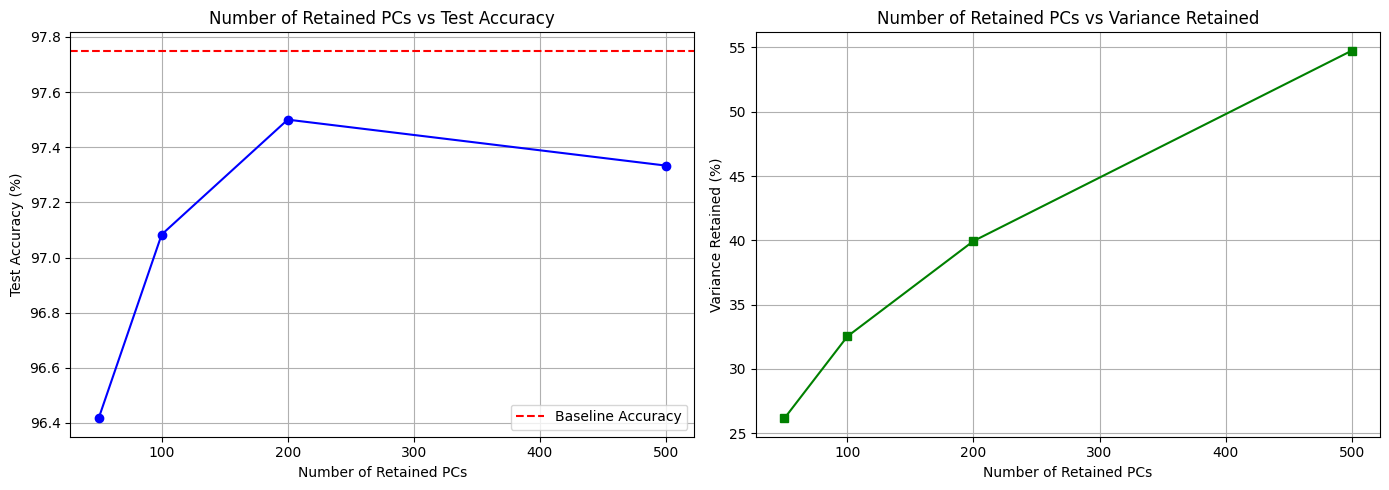

In [19]:
pca_results = results_df[results_df['Method'] != 'Original']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize= (14,5))

#Number of retained PCs vs Test Accuracy
ax1.plot(pca_results['Input Dimensions'], pca_results['Test Accuracy %'], marker='o', color='b')
ax1.axhline(y=baseline_acc * 100, color='r', linestyle='--', label='Baseline Accuracy')
ax1.set_title('Number of Retained PCs vs Test Accuracy')
ax1.set_xlabel('Number of Retained PCs')
ax1.set_ylabel('Test Accuracy (%)')
ax1.grid(True)
ax1.legend()

#Number of retained PCs vs Variance retained
ax2.plot(pca_results['Input Dimensions'], pca_results['Variance Retained %'], marker='s', color='g')
ax2.set_title('Number of Retained PCs vs Variance Retained')
ax2.set_xlabel('Number of Retained PCs')
ax2.set_ylabel('Variance Retained (%)')
ax2.grid(True)

plt.tight_layout()
plt.show()